In [ ]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/playground-series-s6e9/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e9/train.csv
/kaggle/input/competitions/playground-series-s6e9/test.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder
import lightgbm as lgb
import xgboost as xgb
import catboost as cb
import warnings

warnings.filterwarnings("ignore")
sns.set(style="whitegrid", font_scale=1.1)

# train=pd.read_csv("/kaggle/input/competitions/playground-series-s6e9/train.csv")
# test=pd.read_csv("/kaggle/input/competitions/playground-series-s6e9/test.csv")
train=pd.read_csv("train.csv")
test=pd.read_csv("test.csv")

target = "Will_Buy_EV"
feature_cols = [c for c in train.columns if c not in [target, "id"]]

In [4]:
train.shape

(668665, 15)

In [5]:
train.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  object 
 9   City_Type                    668665 non-null  object 
 10  Current_Car_Type             668665 non-null  object 
 11  Home_Charging_Possible       668665 non-null  object 
 12  Subsidy_Available            668665 non-null  object 
 13 

In [7]:
train.isnull().sum()

id                             0
Age                            0
Annual_Income_USD              0
Daily_Commute_km               0
Number_of_Cars_Owned           0
Charging_Stations_Near_Home    0
Charging_Stations_Near_Work    0
Environmental_Concern_Level    0
Gender                         0
City_Type                      0
Current_Car_Type               0
Home_Charging_Possible         0
Subsidy_Available              0
Range_Anxiety_Level            0
Will_Buy_EV                    0
dtype: int64

In [8]:
train.duplicated().sum()

np.int64(0)

In [9]:
train.columns

Index(['id', 'Age', 'Annual_Income_USD', 'Daily_Commute_km',
       'Number_of_Cars_Owned', 'Charging_Stations_Near_Home',
       'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender',
       'City_Type', 'Current_Car_Type', 'Home_Charging_Possible',
       'Subsidy_Available', 'Range_Anxiety_Level', 'Will_Buy_EV'],
      dtype='object')

In [10]:
train["Gender"].value_counts()

Gender
Male      367954
Female    295427
Other       5284
Name: count, dtype: int64

In [11]:
train["City_Type"].value_counts()

City_Type
Urban       289305
Suburban    255377
Rural       123983
Name: count, dtype: int64

In [12]:
train["Current_Car_Type"].value_counts()

Current_Car_Type
Sedan        303459
SUV          246545
Hatchback     79438
Truck         39223
Name: count, dtype: int64

In [13]:
train["Home_Charging_Possible"].value_counts()

Home_Charging_Possible
Yes    462677
No     205988
Name: count, dtype: int64

In [14]:
train["Subsidy_Available"].value_counts()

Subsidy_Available
Yes    419909
No     248756
Name: count, dtype: int64

In [15]:
train["Range_Anxiety_Level"].value_counts()

Range_Anxiety_Level
Low       603972
Medium     62499
High        2194
Name: count, dtype: int64

In [16]:
train["Will_Buy_EV"].value_counts()  

Will_Buy_EV
No     551886
Yes    116779
Name: count, dtype: int64

<Axes: xlabel='Gender'>

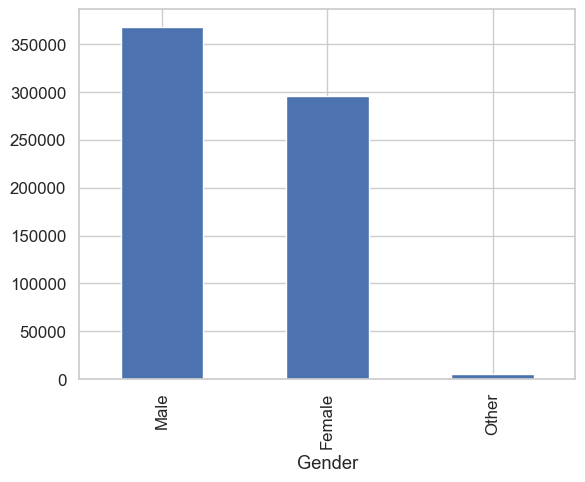

In [17]:
train["Gender"].value_counts().plot(kind="bar")

<Axes: xlabel='City_Type'>

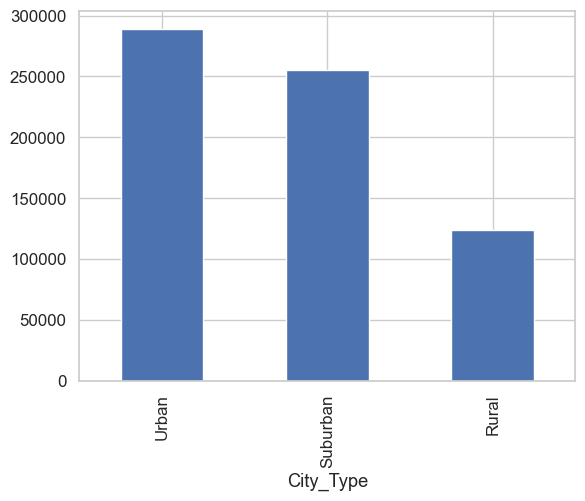

In [18]:
train["City_Type"].value_counts().plot(kind="bar")

<Axes: xlabel='Current_Car_Type'>

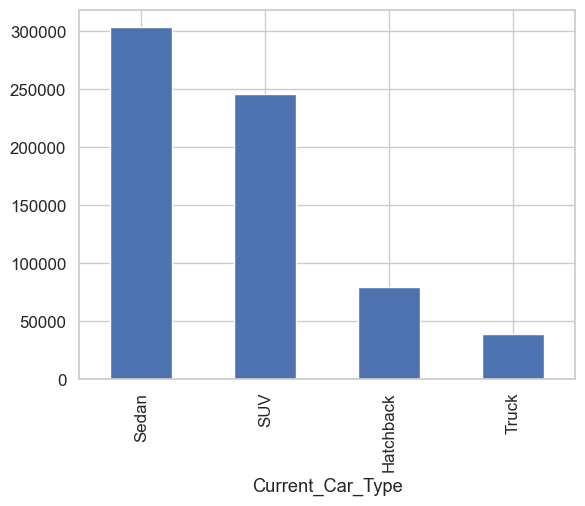

In [19]:
train["Current_Car_Type"].value_counts().plot(kind="bar")

<Axes: xlabel='Home_Charging_Possible'>

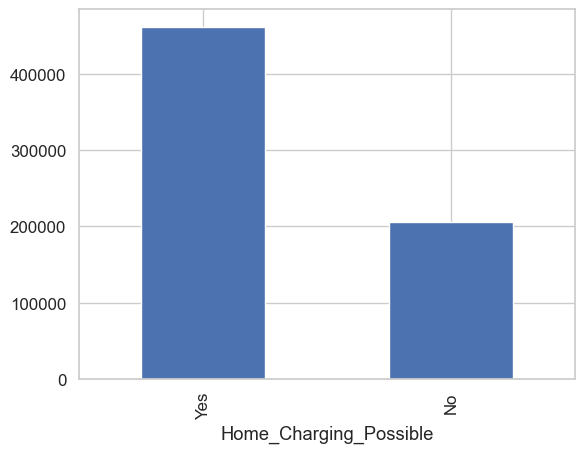

In [20]:
train["Home_Charging_Possible"].value_counts().plot(kind="bar")

<Axes: xlabel='Subsidy_Available'>

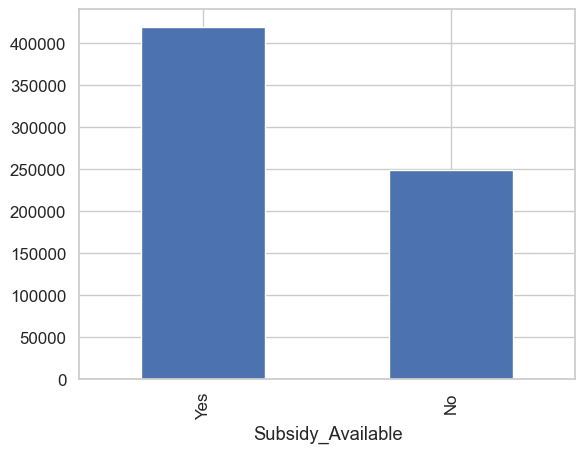

In [21]:
train["Subsidy_Available"].value_counts().plot(kind="bar")

<Axes: xlabel='Range_Anxiety_Level'>

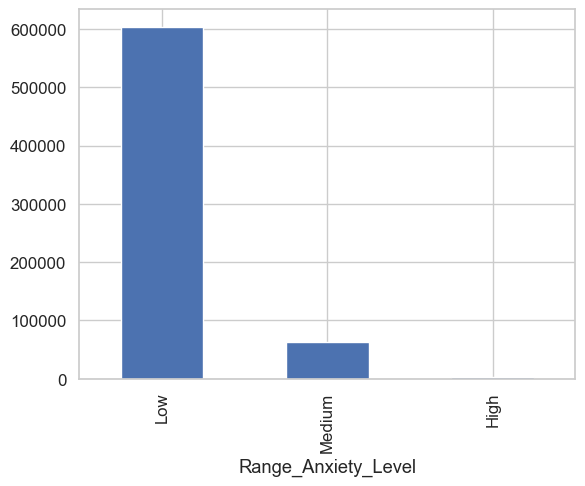

In [22]:
train["Range_Anxiety_Level"].value_counts().plot(kind="bar")

<Axes: xlabel='Will_Buy_EV'>

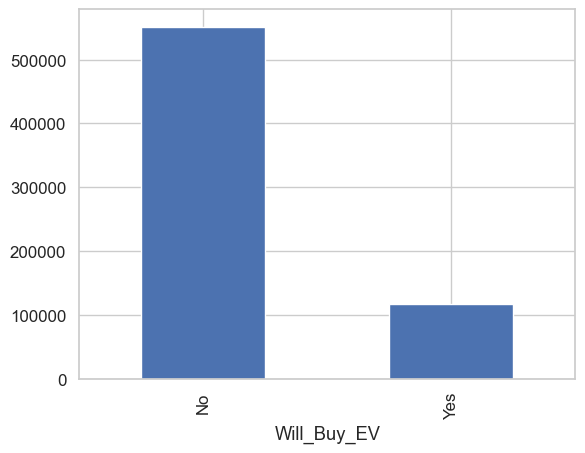

In [23]:
train["Will_Buy_EV"].value_counts().plot(kind="bar")

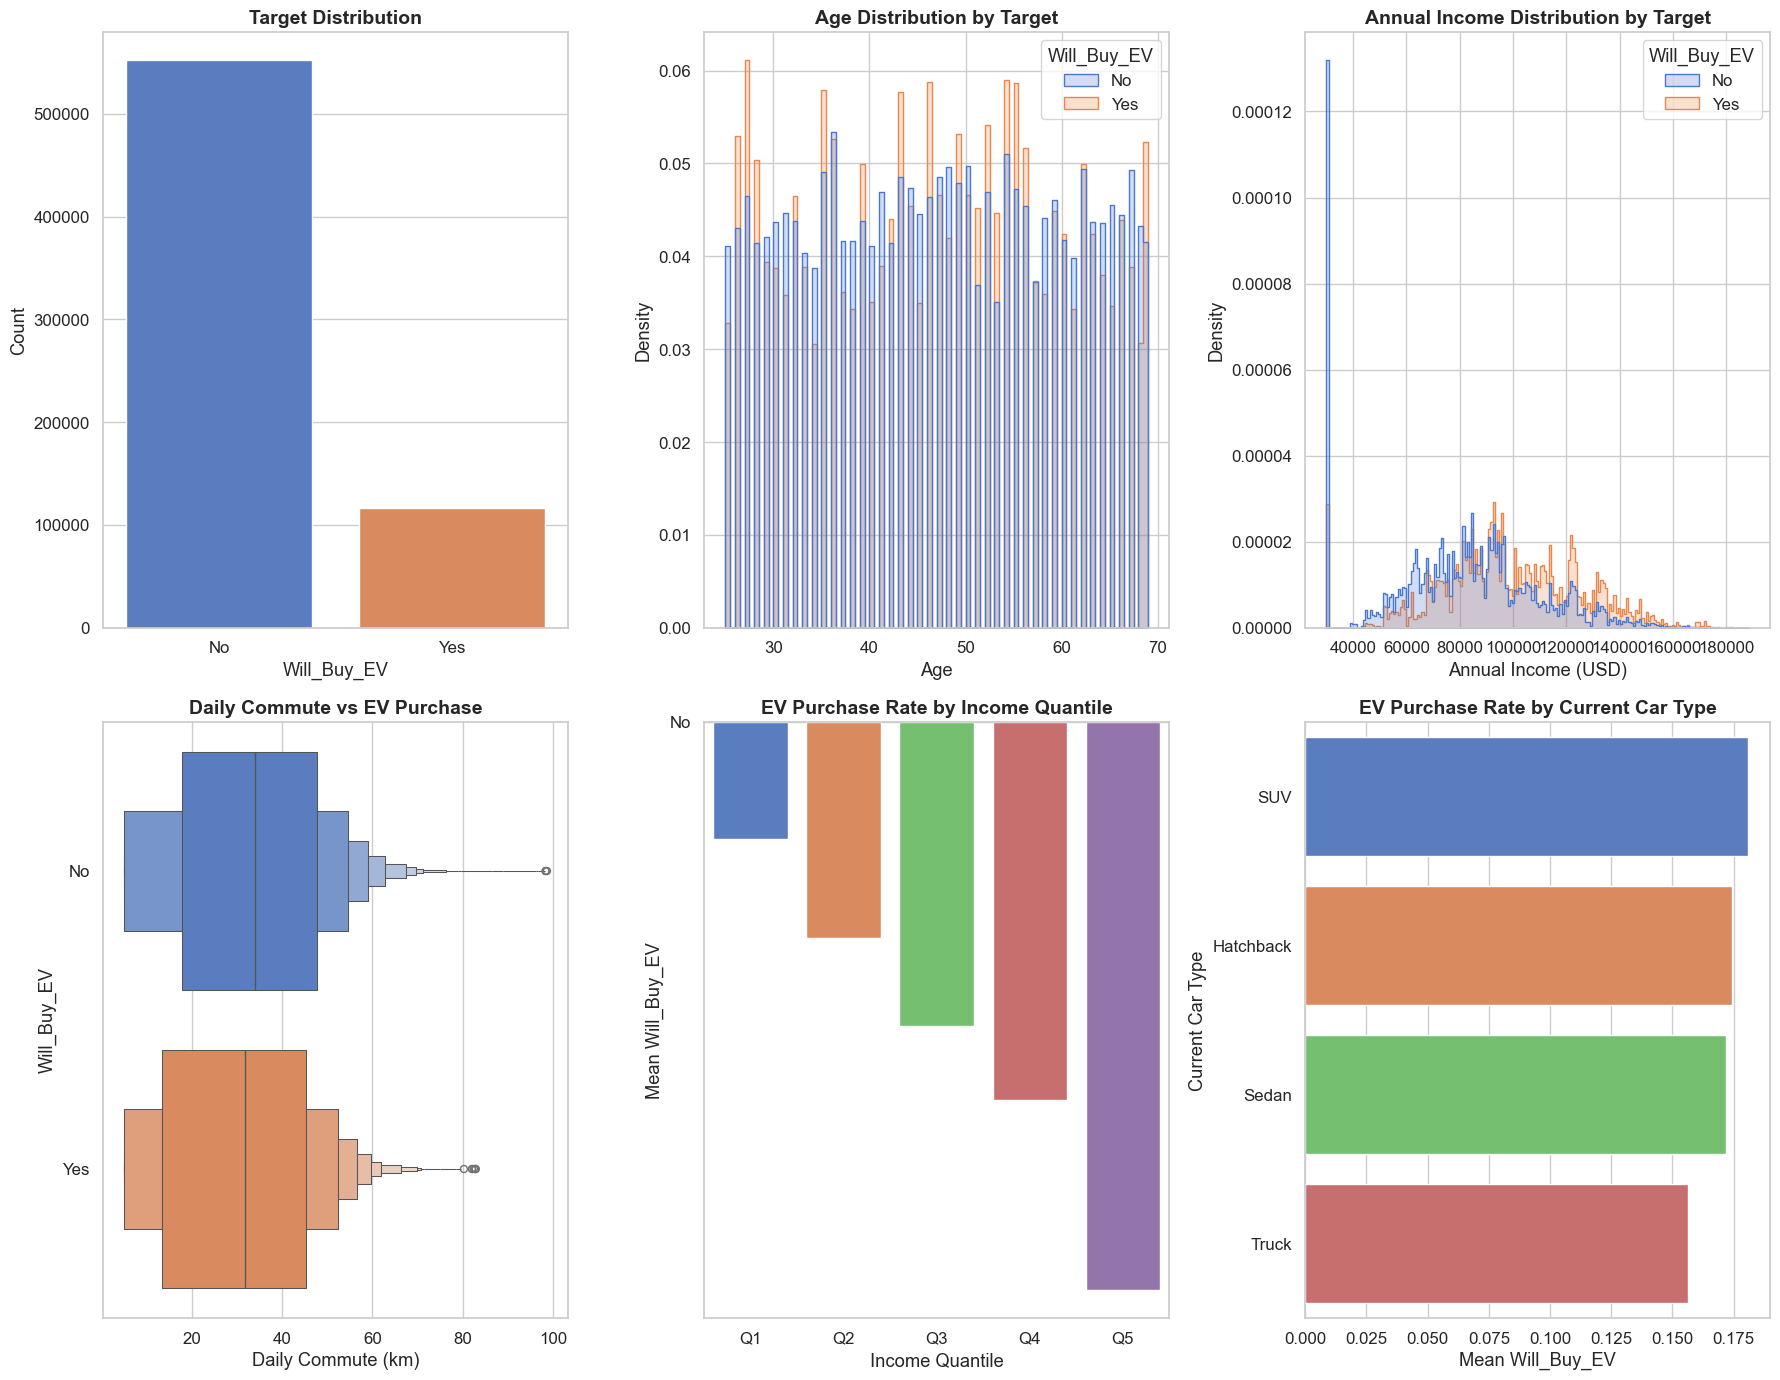

In [24]:
cat_cols = ["Gender", "City_Type", "Current_Car_Type", "Home_Charging_Possible", "Subsidy_Available", "Range_Anxiety_Level"]
num_cols = [c for c in feature_cols if c not in cat_cols]

fig = plt.figure(figsize=(18, 14))

ax1 = plt.subplot(2, 3, 1)
sns.countplot(data=train, x=target, ax=ax1, palette="muted")
ax1.set_title("Target Distribution", fontsize=14, weight="bold")
ax1.set_xlabel("Will_Buy_EV")
ax1.set_ylabel("Count")

ax2 = plt.subplot(2, 3, 2)
sns.histplot(data=train, x="Age", hue=target, element="step", stat="density", common_norm=False, ax=ax2, palette="muted")
ax2.set_title("Age Distribution by Target", fontsize=14, weight="bold")
ax2.set_xlabel("Age")
ax2.set_ylabel("Density")

ax3 = plt.subplot(2, 3, 3)
sns.histplot(data=train, x="Annual_Income_USD", hue=target, element="step", stat="density", common_norm=False, ax=ax3, palette="muted")
ax3.set_title("Annual Income Distribution by Target", fontsize=14, weight="bold")
ax3.set_xlabel("Annual Income (USD)")
ax3.set_ylabel("Density")

ax4 = plt.subplot(2, 3, 4)
sns.boxenplot(data=train, x="Daily_Commute_km", y=target, orient="h", ax=ax4, palette="muted")
ax4.set_title("Daily Commute vs EV Purchase", fontsize=14, weight="bold")
ax4.set_xlabel("Daily Commute (km)")
ax4.set_ylabel("Will_Buy_EV")

income_bins = pd.qcut(train["Annual_Income_USD"], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
train["Income_Quantile"] = income_bins

ax5 = plt.subplot(2, 3, 5)
sns.barplot(data=train, x="Income_Quantile", y=target, ax=ax5, palette="muted", errorbar=None)
ax5.set_title("EV Purchase Rate by Income Quantile", fontsize=14, weight="bold")
ax5.set_xlabel("Income Quantile")
ax5.set_ylabel("Mean Will_Buy_EV")

grouped = train.groupby("Current_Car_Type")[target].apply(lambda x: (x == "Yes").mean()).sort_values(ascending=False).reset_index()
ax6 = plt.subplot(2, 3, 6)
sns.barplot(data=grouped, x=target, y="Current_Car_Type", ax=ax6, palette="muted")
ax6.set_title("EV Purchase Rate by Current Car Type", fontsize=14, weight="bold")
ax6.set_xlabel("Mean Will_Buy_EV")
ax6.set_ylabel("Current Car Type")

plt.tight_layout()
plt.show()

In [25]:
train["Income_per_Car"] = train["Annual_Income_USD"] / (train["Number_of_Cars_Owned"] + 1)
test["Income_per_Car"] = test["Annual_Income_USD"] / (test["Number_of_Cars_Owned"] + 1)

train["Charging_Near_Home_Work"] = train["Charging_Stations_Near_Home"] + train["Charging_Stations_Near_Work"]
test["Charging_Near_Home_Work"] = test["Charging_Stations_Near_Home"] + test["Charging_Stations_Near_Work"]

train["Commute_Burden"] = train["Daily_Commute_km"] / (train["Annual_Income_USD"] + 1e3)
test["Commute_Burden"] = test["Daily_Commute_km"] / (test["Annual_Income_USD"] + 1e3)

home_charge_binary = (train["Home_Charging_Possible"] == "Yes").astype(int)
train["Charging_Infrastructure_Score"] = (
    train["Charging_Stations_Near_Home"] * home_charge_binary +
    train["Charging_Stations_Near_Work"]
)
home_charge_binary_test = (test["Home_Charging_Possible"] == "Yes").astype(int)
test["Charging_Infrastructure_Score"] = (
    test["Charging_Stations_Near_Home"] * home_charge_binary_test +
    test["Charging_Stations_Near_Work"]
)

subsidy_binary = (train["Subsidy_Available"] == "Yes").astype(int)
train["Subsidy_Income_Interaction"] = subsidy_binary * train["Annual_Income_USD"]
subsidy_binary_test = (test["Subsidy_Available"] == "Yes").astype(int)
test["Subsidy_Income_Interaction"] = subsidy_binary_test * test["Annual_Income_USD"]

train["Env_Commute_Interaction"] = train["Environmental_Concern_Level"] * train["Daily_Commute_km"]
test["Env_Commute_Interaction"] = test["Environmental_Concern_Level"] * test["Daily_Commute_km"]

range_order = {"Low": 0, "Medium": 1, "High": 2}
range_anxiety_num = train["Range_Anxiety_Level"].map(range_order).fillna(1).astype(int)
train["Range_Anxiety_Inv"] = 1 / (range_anxiety_num + 1)

range_anxiety_num_test = test["Range_Anxiety_Level"].map(range_order).fillna(1).astype(int)
test["Range_Anxiety_Inv"] = 1 / (range_anxiety_num_test + 1)

agg_income_city = train.groupby("City_Type")["Annual_Income_USD"].transform("mean")
agg_ev_city = train.groupby("City_Type")[target].apply(lambda x: (x == "Yes").mean())
agg_ev_car = train.groupby("Current_Car_Type")[target].apply(lambda x: (x == "Yes").mean())

train["City_Mean_Income"] = agg_income_city
train["City_EV_Rate"] = agg_ev_city
train["Car_Type_EV_Rate"] = agg_ev_car

city_income_map = train.groupby("City_Type")["Annual_Income_USD"].mean()
city_ev_map = train.groupby("City_Type")[target].apply(lambda x: (x == "Yes").mean())
car_ev_map = train.groupby("Current_Car_Type")[target].apply(lambda x: (x == "Yes").mean())

test["City_Mean_Income"] = test["City_Type"].map(city_income_map)
test["City_EV_Rate"] = test["City_Type"].map(city_ev_map)
test["Car_Type_EV_Rate"] = test["Current_Car_Type"].map(car_ev_map)

new_num_features = [
    "Income_per_Car",
    "Charging_Near_Home_Work",
    "Commute_Burden",
    "Charging_Infrastructure_Score",
    "Subsidy_Income_Interaction",
    "Env_Commute_Interaction",
    "Range_Anxiety_Inv",
    "City_Mean_Income",
    "City_EV_Rate",
    "Car_Type_EV_Rate",
]

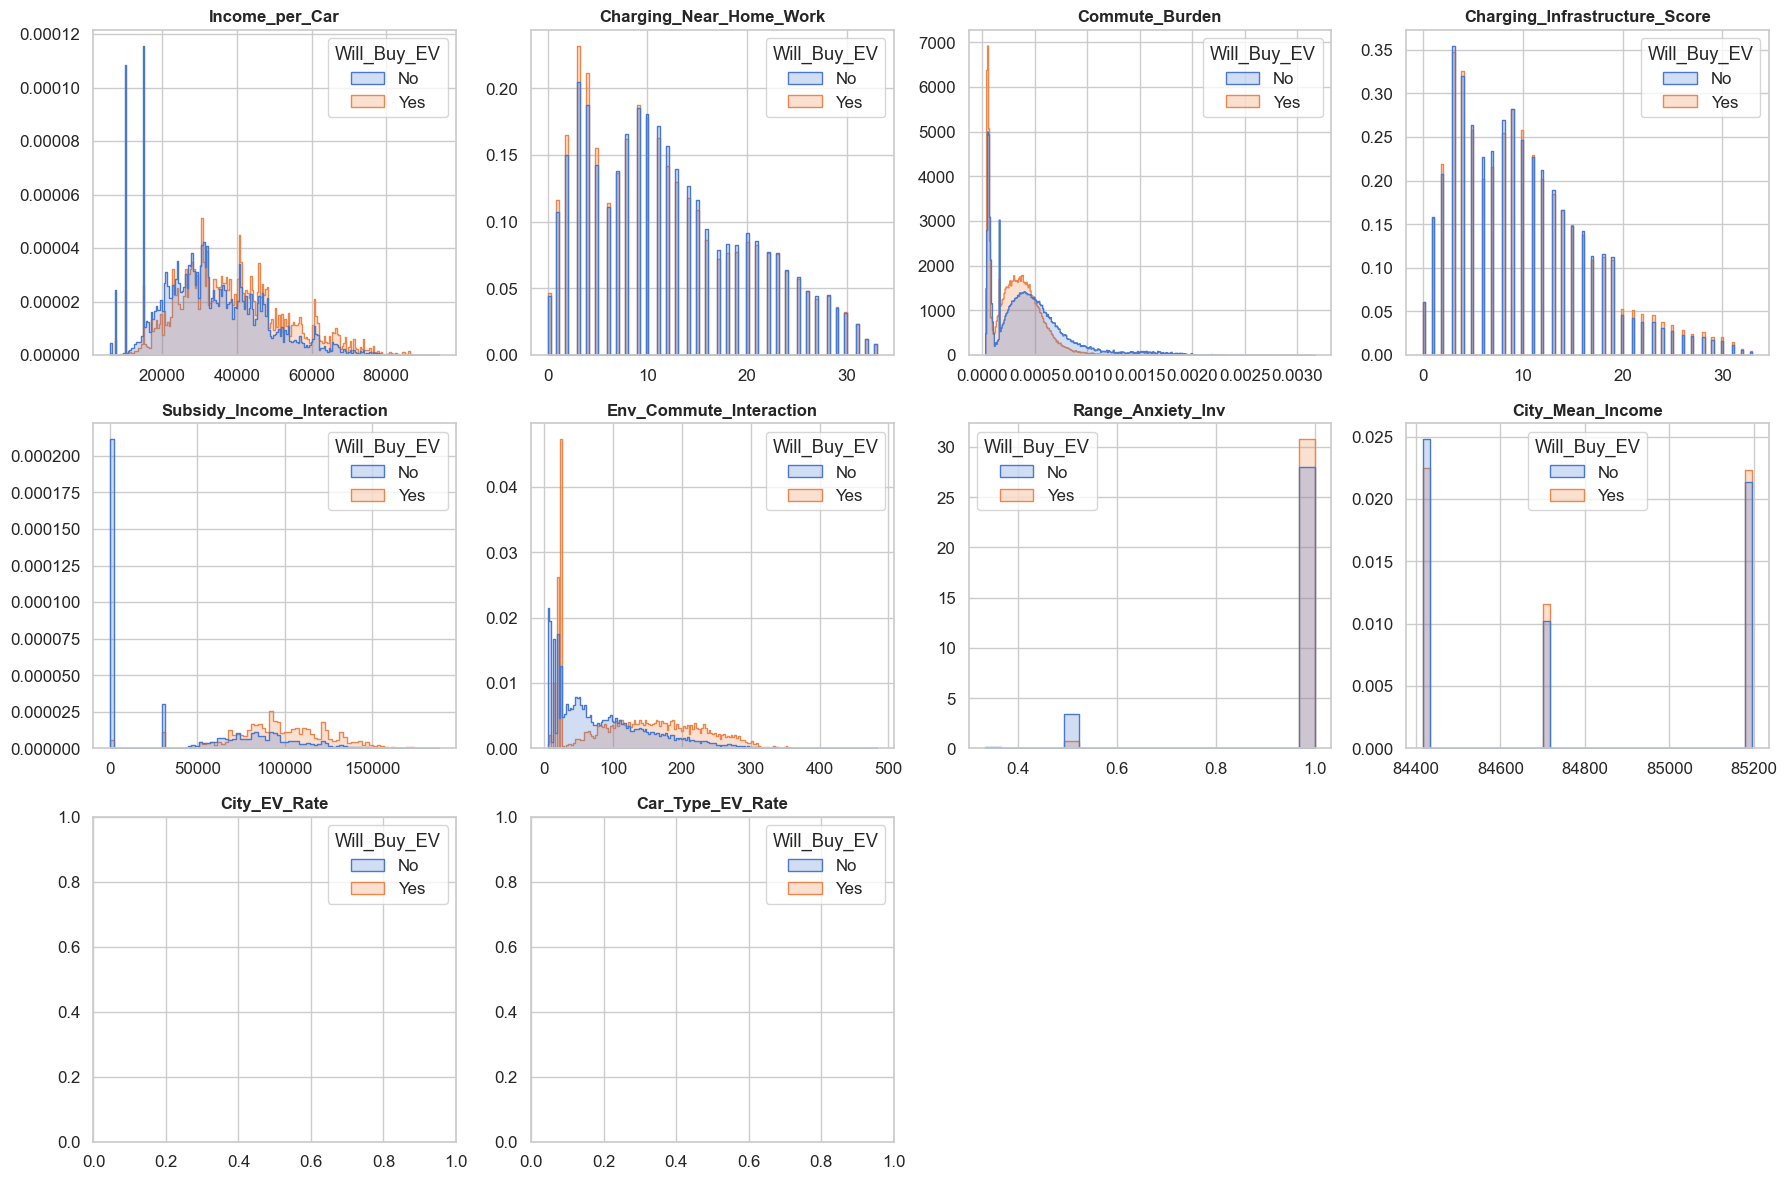

In [26]:
fig2 = plt.figure(figsize=(18, 12))

for i, col in enumerate(new_num_features, 1):
    ax = plt.subplot(3, 4, i)
    sns.histplot(
        data=train,
        x=col,
        hue=target,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax,
        palette="muted"
    )
    ax.set_title(col, fontsize=12, weight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

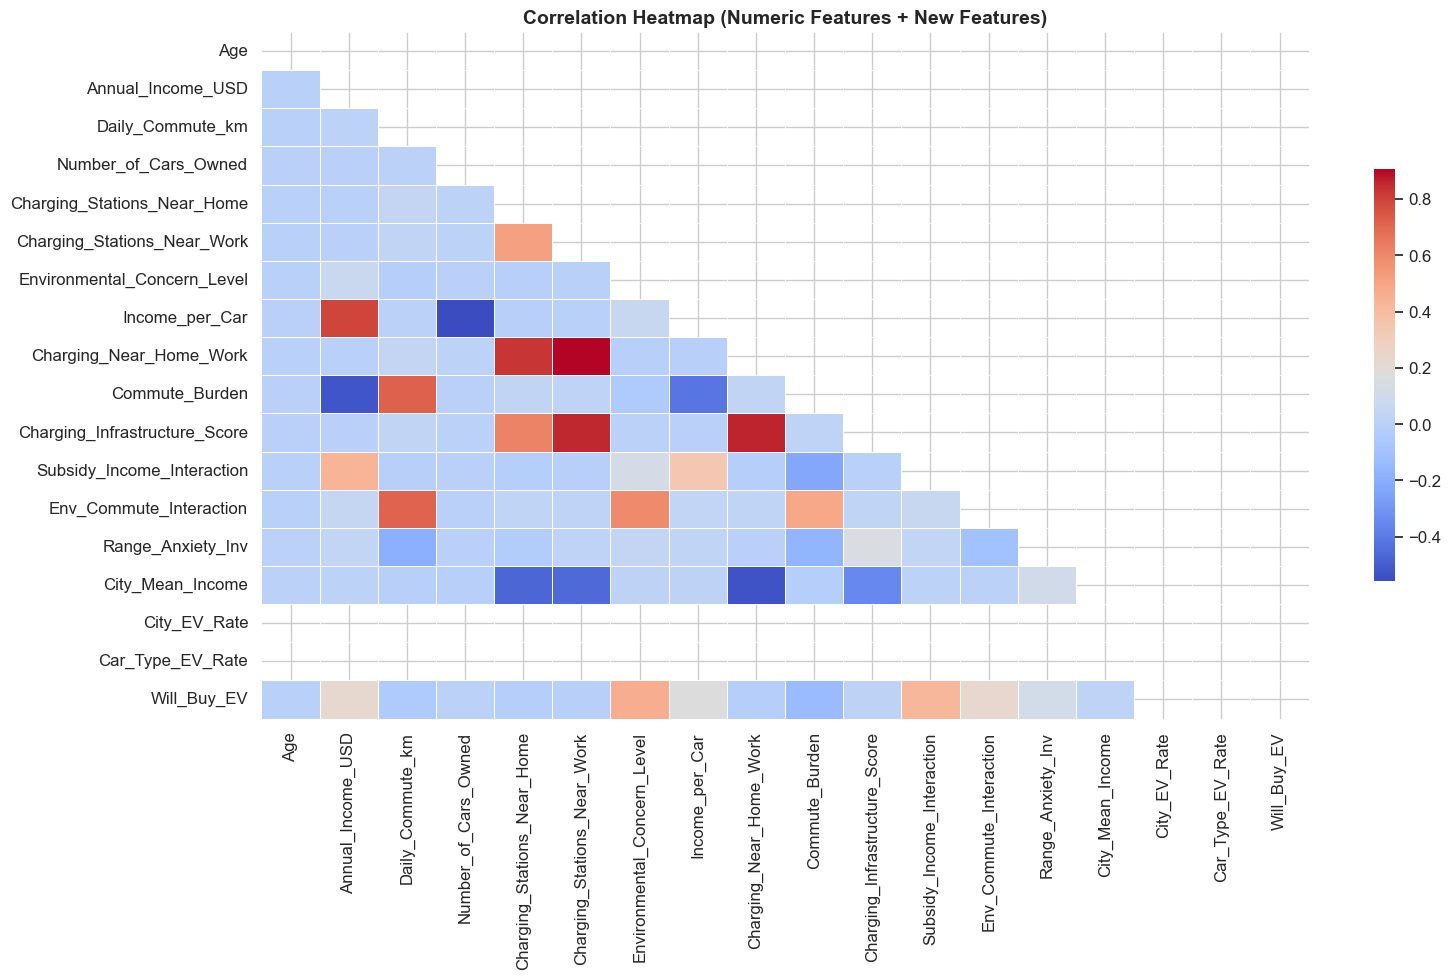

In [27]:
all_num_cols = num_cols + new_num_features

corr_df = train[all_num_cols + [target]].copy()
corr_df[target] = (corr_df[target] == "Yes").astype(int)

corr_matrix = corr_df.corr()

plt.figure(figsize=(16, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    annot=False,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"shrink": 0.6}
)
plt.title("Correlation Heatmap (Numeric Features + New Features)", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

In [28]:
if "id" in train.columns:
    train_ids = train["id"]
    test_ids = test["id"]
else:
    train_ids = np.arange(len(train))
    test_ids = np.arange(len(test))

X = train[feature_cols].copy()
y = (train[target] == "Yes").astype(int)
X_test = test[feature_cols].copy()

cat_cols = ["Gender", "City_Type", "Current_Car_Type", "Home_Charging_Possible", "Subsidy_Available", "Range_Anxiety_Level"]
num_cols = [c for c in feature_cols if c not in cat_cols]

label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    combined = pd.concat([X[col], X_test[col]], axis=0).astype(str)
    le.fit(combined)
    X[col] = le.transform(X[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))
    label_encoders[col] = le

feature_cols = [c for c in X.columns]

In [ ]:
N_FOLDS = 7
SEED = 42

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_lgb = np.zeros(len(X))
oof_xgb = np.zeros(len(X))
oof_cb = np.zeros(len(X))

preds_lgb = np.zeros(len(X_test))
preds_xgb = np.zeros(len(X_test))
preds_cb = np.zeros(len(X_test))

auc_lgb_list = []
auc_xgb_list = []
auc_cb_list = []

lgb_params = {
    "objective": "binary",
    "metric": "auc",
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": 6,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 5,
    "min_child_samples": 50,
    "seed": SEED,
    "verbose": -1,
}

xgb_params = {
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "learning_rate": 0.05,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "seed": SEED,
    "tree_method": "hist",
    "n_jobs": -1,
}

cb_params = {
    "iterations": 10000,
    "learning_rate": 0.05,
    "depth": 6,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "random_seed": SEED,
    "od_type": "Iter",
    "od_wait": 200,
    "task_type": "CPU",
    "verbose": 0,
}

te_cols = [c for c in cat_cols]

def target_encode_fold(train_idx, val_idx, X, y, te_cols, k=5):
    global_mean = y.mean()
    encoded = X.copy()
    for col in te_cols:
        agg = X.iloc[train_idx].copy()
        agg["y"] = y.iloc[train_idx]
        stats = agg.groupby(col)["y"].agg(["mean", "count"])
        smooth = (k * global_mean + stats["mean"] * stats["count"]) / (k + stats["count"])
        encoded.loc[train_idx, col + "_te"] = X.iloc[train_idx][col].map(smooth)
        encoded.loc[val_idx, col + "_te"] = X.iloc[val_idx][col].map(smooth)
        encoded[col + "_te"] = encoded[col + "_te"].fillna(global_mean)
    return encoded

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    print(f"Fold {fold+1}")

    X_te = target_encode_fold(train_idx, val_idx, X, y, te_cols, k=5)
    X_test_te = X_test.copy()
    global_mean = y.mean()
    agg_full = X.copy()
    agg_full["y"] = y
    for col in te_cols:
        stats = agg_full.groupby(col)["y"].agg(["mean", "count"])
        smooth = (5 * global_mean + stats["mean"] * stats["count"]) / (5 + stats["count"])
        X_test_te[col + "_te"] = X_test_te[col].map(smooth).fillna(global_mean)

    feat_now = [c for c in X_te.columns if c not in [target]]
    
    X_train = X_te.iloc[train_idx][feat_now]
    X_val = X_te.iloc[val_idx][feat_now]
    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]
    X_test_now = X_test_te[feat_now]

    model_lgb = lgb.LGBMClassifier(**lgb_params, n_estimators=2000)
    model_lgb.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(200, verbose=False)]
    )
    p_val_lgb = model_lgb.predict_proba(X_val)[:, 1]
    oof_lgb[val_idx] = p_val_lgb
    preds_lgb += model_lgb.predict_proba(X_test_now)[:, 1] / N_FOLDS
    auc_lgb = roc_auc_score(y_val, p_val_lgb)
    auc_lgb_list.append(auc_lgb)

    model_xgb = xgb.XGBClassifier(
        **xgb_params,
        n_estimators=2000,
        early_stopping_rounds=200
    )
    model_xgb.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )
    p_val_xgb = model_xgb.predict_proba(X_val)[:, 1]
    oof_xgb[val_idx] = p_val_xgb
    preds_xgb += model_xgb.predict_proba(X_test_now)[:, 1] / N_FOLDS
    auc_xgb = roc_auc_score(y_val, p_val_xgb)
    auc_xgb_list.append(auc_xgb)

    model_cb = cb.CatBoostClassifier(**cb_params)
    model_cb.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        use_best_model=True
    )
    p_val_cb = model_cb.predict_proba(X_val)[:, 1]
    oof_cb[val_idx] = p_val_cb
    preds_cb += model_cb.predict_proba(X_test_now)[:, 1] / N_FOLDS
    auc_cb = roc_auc_score(y_val, p_val_cb)
    auc_cb_list.append(auc_cb)

    print(f"  LGB AUC: {auc_lgb:.6f}, XGB AUC: {auc_xgb:.6f}, CB AUC: {auc_cb:.6f}")

print("OOF AUCs -> LGB:", np.mean(auc_lgb_list), "XGB:", np.mean(auc_xgb_list), "CB:", np.mean(auc_cb_list))

In [ ]:
w_lgb = 1/3
w_xgb = 1/3
w_cb = 1/3

oof_ens = w_lgb * oof_lgb + w_xgb * oof_xgb + w_cb * oof_cb
auc_ens = roc_auc_score(y, oof_ens)
print("Equal-weight ensemble OOF AUC:", auc_ens)

best_w = (w_lgb, w_xgb, w_cb)
best_auc = auc_ens

for _ in range(5):
    improved = False
    for dw in np.linspace(-0.1, 0.1, 9):
        for dv in np.linspace(-0.1, 0.1, 9):
            w1 = best_w[0] + dw
            w2 = best_w[1] + dv
            w3 = 1 - w1 - w2
            if min(w1, w2, w3) < 0:
                continue
            oof_tmp = w1 * oof_lgb + w2 * oof_xgb + w3 * oof_cb
            auc_tmp = roc_auc_score(y, oof_tmp)
            if auc_tmp > best_auc:
                best_auc = auc_tmp
                best_w = (w1, w2, w3)
                improved = True
    if not improved:
        break

print("Best weights:", best_w, "Best OOF AUC:", best_auc)

final_preds = best_w[0] * preds_lgb + best_w[1] * preds_xgb + best_w[2] * preds_cb

Equal-weight ensemble OOF AUC: 0.9420808727040371
Best weights: (np.float64(0.3583333333333333), np.float64(0.30833333333333335), np.float64(0.33333333333333337)) Best OOF AUC: 0.9420811491099432


In [ ]:
submission=pd.read_csv("/kaggle/input/competitions/playground-series-s6e9/sample_submission.csv")
submission["Will_Buy_EV"]=final_preds
submission.head()

,id,Will_Buy_EV
0,668665,0.008762
1,668666,0.014794
2,668667,0.004115
3,668668,0.002597
4,668669,0.016168


In [ ]:
submission.to_csv("submission_file.csv",index=False)